# 06 — Fogo, cobertura da terra e transformação socioambiental na Amazônia

**TCC — Uma análise do sistema atmosfera-floresta amazônico sob a ótica da teoria do caos**  
**Regiões:** bacia hidrográfica do Xingu e caixa geográfica do Baixo Tapajós  
**Período:** 1990–2024 · **Escala temporal:** anual

## Perguntas de pesquisa

1. Como evoluíram a área atingida pelo fogo e a cobertura florestal em cada recorte?
2. Quanto do fogo mapeado coincide espacialmente com formações florestais e com classes de uso agropecuário?
3. Quais transformações territoriais documentadas na literatura ajudam a **contextualizar**, sem demonstrar causalidade, esses padrões?

**Princípio científico:** área queimada, perda de cobertura florestal e desmatamento são conceitos diferentes. O fogo pode ocorrer sob regimes ecológicos e sociais distintos; coincidência espacial ou temporal não implica causalidade. Este notebook **não** testa caos, *tipping points* nem causalidade entre fogo e clima.

### Fontes e versões (verificadas em outubro de 2026)

- [MapBiomas Fogo — mapeamento anual](https://brasil.mapbiomas.org/iniciativas-e-produtos/fogo/mapeamento-anual/anual/) — Coleção **5.1**, bandas `burned_area_ANO`, 1985–2025.
- [MapBiomas Brasil — Cobertura e Uso da Terra 30 m](https://brasil.mapbiomas.org/iniciativas-e-produtos/cobertura-e-uso-da-terra/cobertura-30m/cobertura/) — Coleção **11**, bandas `classification_ANO`, 1985–2025.
- [Repositório Caos](https://github.com/ThallesCansi/Caos) e configurações [`xingu_1990_2024.yaml`](https://github.com/ThallesCansi/Caos/blob/main/configs/xingu_1990_2024.yaml) / [`tapajos_1990_2024.yaml`](https://github.com/ThallesCansi/Caos/blob/main/configs/tapajos_1990_2024.yaml).

> **Estado inicial:** a exportação do Google Earth Engine (GEE) fica desativada por padrão. Para executar a análise com dados reais, você precisará autorizar o GEE e importar os dois CSVs exportados. **Não há dados simulados apresentados como resultados ambientais.**

## 1. Configuração e organização do trabalho

Coloque este notebook **na raiz do clone local** do repositório `Caos`, ao lado dos notebooks `04_...` e `05_...`.

Fluxo: **recorte do repositório → extração explícita no GEE → CSV anual → controle de qualidade → indicadores → gráficos → contextualização histórica.**

A aquisição de raster nacional em 30 m por 35 anos seria muito pesada; o GEE calcula estatísticas diretamente em cada região e exporta apenas tabelas pequenas. Não é necessário baixar os rasters inteiros.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import yaml
    import geopandas as gpd
    from shapely.geometry import box, mapping
except ImportError as exc:
    raise ImportError('Execute na raiz do projeto com `uv sync` e abra o Jupyter com o ambiente do projeto.') from exc

plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True, 'grid.alpha': 0.2})

def localizar_raiz():
    for pasta in (Path.cwd(), *Path.cwd().parents):
        if (pasta / 'pyproject.toml').exists() and (pasta / 'configs').is_dir():
            return pasta
    raise FileNotFoundError('Abra este notebook na raiz do clone de Caos (pyproject.toml + configs/).')

RAIZ = localizar_raiz()
ANOS = list(range(1990, 2025))
DADOS_DIR = RAIZ / 'data' / 'processed' / 'mapbiomas'
FIG_DIR = RAIZ / 'reports' / 'figures' / 'mapbiomas'
TAB_DIR = RAIZ / 'reports' / 'tables' / 'mapbiomas'
SALVAR_RESULTADOS = True  # apenas arquivos derivados; sem downloads de dados brutos

ARQUIVOS_CONFIG = {
    'xingu': RAIZ / 'configs/xingu_1990_2024.yaml',
    'baixo_tapajos': RAIZ / 'configs/tapajos_1990_2024.yaml',
}
CONFIGS = {}
for chave, arquivo in ARQUIVOS_CONFIG.items():
    if not arquivo.exists():
        raise FileNotFoundError(f'Configuração do repositório não encontrada: {arquivo}')
    with arquivo.open(encoding='utf-8') as f:
        CONFIGS[chave] = yaml.safe_load(f)

print('Raiz:', RAIZ)
print('Período:', ANOS[0], 'a', ANOS[-1])
print('Arquivos de configuração:', [p.name for p in ARQUIVOS_CONFIG.values()])

Raiz: /home/ABTLUS/thalles24006/Documentos/ILUM/TCC/Caos
Período: 1990 a 2024
Arquivos de configuração: ['xingu_1990_2024.yaml', 'tapajos_1990_2024.yaml']


## 2. Delimitação espacial — exatamente a referência do ERA5

- **Xingu:** o retângulo de aquisição ERA5 **não** é a área científica; a região de análise é o polígono da bacia BHB250/IBGE (código Otto 642), identificado no YAML como `spatial.basin_source`.
- **Baixo Tapajós:** a própria **caixa retangular** `spatial.area` é a região de análise; isso não equivale à união dos municípios de Santarém, Belterra e Mojuí dos Campos.

A análise MapBiomas usa esses limites geográficos, mas suas estatísticas são calculadas em pixels de ~30 m, não nas células ERA5 de 0,25°. A equivalência se refere ao **recorte**, não à resolução ou à ponderação dos valores climáticos.

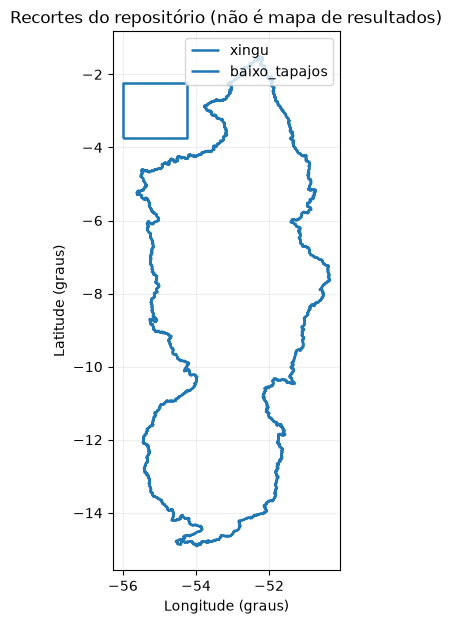

xingu | área ERA5 [N, W, S, E] = [-1.25, -55.75, -15.0, -50.25] | polígono pronto = True
baixo_tapajos | área ERA5 [N, W, S, E] = [-2.25, -56.0, -3.75, -54.25] | polígono pronto = True


In [2]:
def poligono_regiao(chave):
    cfg = CONFIGS[chave]
    espacial = cfg['spatial']
    if chave == 'xingu':
        caminho = RAIZ / espacial['basin_source']
        if not caminho.exists():
            raise FileNotFoundError(
                f'Limite BHB250 do Xingu ausente: {caminho}. '
                'Recupere-o pelo pipeline cartográfico do repositório antes de exportar dados do Xingu.'
            )
        base = gpd.read_file(caminho)
        if base.empty or base.crs is None:
            raise ValueError(f'Polígono do Xingu vazio ou sem CRS: {caminho}')
        geom = base.to_crs(4326).geometry.union_all()
        if geom.is_empty or not geom.is_valid:
            raise ValueError('Geometria do Xingu vazia/inválida; revisar arquivo vetorial.')
        return geom
    norte, oeste, sul, leste = map(float, espacial['area'])
    if not (norte > sul and leste > oeste):
        raise ValueError('Ordem de bbox inválida; esperado [N, W, S, E]')
    return box(oeste, sul, leste, norte)

GEOMETRIAS = {}
for chave in CONFIGS:
    try:
        GEOMETRIAS[chave] = poligono_regiao(chave)
    except FileNotFoundError as exc:
        print(f'[ATENÇÃO] {exc}')

fig, ax = plt.subplots(figsize=(8, 7))
for chave, geom in GEOMETRIAS.items():
    gpd.GeoSeries([geom], crs='EPSG:4326').boundary.plot(ax=ax, linewidth=1.8, label=chave)
ax.set(xlabel='Longitude (graus)', ylabel='Latitude (graus)', title='Recortes do repositório (não é mapa de resultados)')
ax.set_aspect('equal')
ax.legend()
plt.show()

for chave, cfg in CONFIGS.items():
    print(chave, '| área ERA5 [N, W, S, E] =', cfg['spatial']['area'],
          '| polígono pronto =', chave in GEOMETRIAS)

## 3. Definição dos indicadores e das classes

**MapBiomas Cobertura 30 m, Coleção 11.** Neste primeiro estudo, adotamos explicitamente:

- **Formações florestais:** códigos `3` (formação florestal) e `6` (floresta alagável). Esta **não** é a classe agregada completa do nível 1, que também inclui formações savânicas e outras fitofisionomias.
- **Agropecuária (uso amplo):** pastagem, culturas agrícolas, silvicultura e mosaico de usos, incluindo seus códigos foliares documentados. Essa classe é usada descritivamente, sem identificar a intenção por trás do fogo.
- **Água mapeada:** classe `33` (rio/lago/oceano); `31` (aquicultura) é mantida fora do indicador de solo não aquático. O denominador principal das porcentagens é **a área geométrica fixa do recorte**, inclusive água, para comparação temporal.

**MapBiomas Fogo, Coleção 5.1:** o indicador `area_queimada_km2` corresponde à extensão de pixels com cicatriz de fogo mapeada no ano, **não** ao número de incêndios ou de focos. `fogo_em_floresta_km2` é a interseção entre área queimada no ano e a **classe de cobertura anual desse mesmo ano**. Não significa, necessariamente, que o pixel era floresta na data do incêndio.

As áreas são somadas via `ee.Image.pixelArea()` (km²) dentro do recorte, com escala de redução de 30 m. Os detalhes da reprojeção e incerteza espacial devem ser documentados na metodologia. Mudanças de cobertura florestal **não** são equivalentes à taxa de desmatamento PRODES.

In [3]:
ASSET_FOGO = ('projects/mapbiomas-public/assets/brazil/fire/collection5_1/'
              'mapbiomas_fire_collection51_annual_burned_v1')
ASSET_COBERTURA = ('projects/mapbiomas-public/assets/brazil/lulc/collection11/'
                   'mapbiomas_brazil_collection11_coverage_v3')

CLASSES_FLORESTA = [3, 6]
CLASSES_AGRO = [9, 14, 15, 18, 19, 20, 21, 35, 36, 39, 40, 41, 46, 47, 48, 62]
CLASSES_AGUA = [31, 33]

COLUNAS_AREA = [
    'area_recorte_km2', 'area_mapeada_km2', 'agua_mapeada_km2',
    'floresta_km2', 'agropecuaria_km2', 'area_queimada_km2',
    'fogo_em_floresta_km2', 'fogo_em_agropecuaria_km2',
]
COLUNAS_CSV = ['regiao', 'ano', *COLUNAS_AREA]

assert not set(CLASSES_FLORESTA).intersection(CLASSES_AGRO)
print('Asset Fogo:', ASSET_FOGO)
print('Asset Cobertura:', ASSET_COBERTURA)
print('Códigos de floresta:', CLASSES_FLORESTA)
print('Códigos de agropecuária:', CLASSES_AGRO)

Asset Fogo: projects/mapbiomas-public/assets/brazil/fire/collection5_1/mapbiomas_fire_collection51_annual_burned_v1
Asset Cobertura: projects/mapbiomas-public/assets/brazil/lulc/collection11/mapbiomas_brazil_collection11_coverage_v3
Códigos de floresta: [3, 6]
Códigos de agropecuária: [9, 14, 15, 18, 19, 20, 21, 35, 36, 39, 40, 41, 46, 47, 48, 62]


## 4. Extração de estatísticas pelo Google Earth Engine — **opcional e explícita**

**Preparação (uma vez):**

1. Crie/autorize sua conta no [Google Earth Engine](https://earthengine.google.com/noncommercial/) e configure um **projeto do Google Cloud habilitado para o GEE**.
2. No ambiente do repositório, instale o cliente Python: `uv add earthengine-api` (ou `uv pip install earthengine-api`, se não quiser mudar o projeto).
3. Ajuste `GEE_PROJECT` abaixo e mude `EXECUTAR_EXPORTACAO_GEE` para `True` **somente quando quiser iniciar tarefas na sua conta**. A célula chama autenticação apenas nesse caso.
4. As duas tarefas exportam arquivos CSV para `Google Drive/Caos_MapBiomas/`. A execução ocorre nos servidores GEE e pode ter filas/quotas.
5. Após a conclusão no [painel Tasks do Earth Engine](https://code.earthengine.google.com/tasks), copie os CSVs para `data/processed/mapbiomas/`, com os nomes exibidos na célula.
6. Volte a `EXECUTAR_EXPORTACAO_GEE = False` nas próximas execuções para não criar exportações duplicadas.

**Não há download automático de arquivos nacionais.** O GEE calcula as agregações por ano em cada recorte; nenhum dado é fabricado quando a exportação ainda não aconteceu.

> **Custo computacional:** 35 anos × 2 regiões em pixels de 30 m pode ser uma tarefa pesada, especialmente na bacia do Xingu. Teste primeiro com `ANOS_EXPORTACAO = [2024]` e uma região; depois use a série completa. Caso o GEE reporte limite de recursos, divida o período em blocos menores ou use `ESCALA_REDUCAO_METROS = 60` apenas como análise exploratória, documentando a perda de resolução.

In [4]:
# CONFIGURAÇÃO EXPLÍCITA PARA INICIAR EXPORTAÇÕES (padrão: NÃO exportar)
EXECUTAR_EXPORTACAO_GEE = False
GEE_PROJECT = ''  # ID do seu projeto Google Cloud habilitado para Earth Engine
REGIOES_EXPORTACAO = ['xingu', 'baixo_tapajos']
ANOS_EXPORTACAO = ANOS  # primeiro teste sugerido: [2024]
ESCALA_REDUCAO_METROS = 30
PASTA_GOOGLE_DRIVE = 'Caos_MapBiomas'


def gerar_exportacoes_gee():
    try:
        import ee
    except ImportError as exc:
        raise ImportError('Instale `earthengine-api` no ambiente do projeto antes de exportar.') from exc
    if not GEE_PROJECT.strip():
        raise ValueError('Preencha GEE_PROJECT com o ID do projeto Cloud registrado no Earth Engine.')
    if ESCALA_REDUCAO_METROS < 30:
        raise ValueError('Não use escala mais fina que o pixel nominal de 30 m.')
    if not ANOS_EXPORTACAO or any(a < 1985 or a > 2025 for a in ANOS_EXPORTACAO):
        raise ValueError('Anos inválidos para as coleções selecionadas (1985–2025).')

    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        print('Iniciando autenticação interativa do Earth Engine...')
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)

    fire = ee.Image(ASSET_FOGO)
    lulc = ee.Image(ASSET_COBERTURA)
    tarefas = []

    def mascara_codigos(imagem, codigos):
        # ee.Image.remap transforma classe codificada em booleano 0/1.
        return imagem.remap(codigos, [1] * len(codigos), 0).eq(1)

    for regiao in REGIOES_EXPORTACAO:
        if regiao not in GEOMETRIAS:
            raise FileNotFoundError(f'Geometria ausente para {regiao}; não pode exportar.')
        roi = ee.Geometry(mapping(GEOMETRIAS[regiao]))
        area_roi = roi.area(maxError=1).divide(1e6)
        feicoes = []
        for ano in ANOS_EXPORTACAO:
            cobertura = lulc.select(f'classification_{ano}')
            fogo = fire.select(f'burned_area_{ano}').eq(1)
            valido = cobertura.mask().gt(0).And(cobertura.neq(0))
            floresta = mascara_codigos(cobertura, CLASSES_FLORESTA)
            agro = mascara_codigos(cobertura, CLASSES_AGRO)
            agua = mascara_codigos(cobertura, CLASSES_AGUA)
            pixel_km2 = ee.Image.pixelArea().divide(1e6)
            bandas = ee.Image.cat([
                pixel_km2.updateMask(valido).rename('area_mapeada_km2'),
                pixel_km2.updateMask(valido.And(agua)).rename('agua_mapeada_km2'),
                pixel_km2.updateMask(valido.And(floresta)).rename('floresta_km2'),
                pixel_km2.updateMask(valido.And(agro)).rename('agropecuaria_km2'),
                pixel_km2.updateMask(fogo).rename('area_queimada_km2'),
                pixel_km2.updateMask(fogo.And(valido).And(floresta)).rename('fogo_em_floresta_km2'),
                pixel_km2.updateMask(fogo.And(valido).And(agro)).rename('fogo_em_agropecuaria_km2'),
            ])
            somas = bandas.reduceRegion(
                reducer=ee.Reducer.sum(), geometry=roi,
                scale=ESCALA_REDUCAO_METROS, crs='EPSG:6933',
                maxPixels=1e13, tileScale=8,
            )
            # Área nula para uma categoria ausente é 0, mas ausência de cobertura
            # deverá ser detectada pela coluna 'area_mapeada_km2' no QC.
            props = {'regiao': regiao, 'ano': ano, 'area_recorte_km2': area_roi}
            for nome in COLUNAS_AREA:
                if nome != 'area_recorte_km2':
                    valor = somas.get(nome)
                    props[nome] = ee.Algorithms.If(ee.Algorithms.IsEqual(valor, None), 0, valor)
            feicoes.append(ee.Feature(None, props))

        nome = f'mapbiomas_{regiao}_{min(ANOS_EXPORTACAO)}_{max(ANOS_EXPORTACAO)}'
        tarefa = ee.batch.Export.table.toDrive(
            collection=ee.FeatureCollection(feicoes),
            description=nome, folder=PASTA_GOOGLE_DRIVE,
            fileNamePrefix=nome, fileFormat='CSV', selectors=COLUNAS_CSV,
        )
        tarefa.start()  # explicitamente habilitado por EXECUTAR_EXPORTACAO_GEE
        tarefas.append(tarefa)
        print(f'Exportação iniciada: {nome}.csv | ID da tarefa: {tarefa.id}')
    return tarefas

if EXECUTAR_EXPORTACAO_GEE:
    TAREFAS_GEE = gerar_exportacoes_gee()
else:
    print('Exportação GEE NÃO iniciada (EXECUTAR_EXPORTACAO_GEE=False).')
    print('CSV(s) esperados:')
    for regiao in CONFIGS:
        print('  ', DADOS_DIR / f'mapbiomas_{regiao}_1990_2024.csv')

Exportação GEE NÃO iniciada (EXECUTAR_EXPORTACAO_GEE=False).
CSV(s) esperados:
   /home/ABTLUS/thalles24006/Documentos/ILUM/TCC/Caos/data/processed/mapbiomas/mapbiomas_xingu_1990_2024.csv
   /home/ABTLUS/thalles24006/Documentos/ILUM/TCC/Caos/data/processed/mapbiomas/mapbiomas_baixo_tapajos_1990_2024.csv


## 5. Importação dos CSVs e controle de qualidade

**Contrato do arquivo** (gerado pela etapa anterior): `regiao, ano, area_recorte_km2, area_mapeada_km2, agua_mapeada_km2, floresta_km2, agropecuaria_km2, area_queimada_km2, fogo_em_floresta_km2, fogo_em_agropecuaria_km2`.

O notebook não atribui zeros a anos inteiros faltantes. Dados ausentes interrompem as conclusões daquela região; um ano **com zero área queimada** é diferente de um ano **não observado**. Se você exportar em blocos, junte os CSVs mantendo uma linha por região/ano.

Saídas derivados apenas em `reports/`; os CSVs originais de exportação não são sobrescritos.

In [5]:
def ler_series_locais():
    quadros = []
    for regiao in CONFIGS:
        caminho = DADOS_DIR / f'mapbiomas_{regiao}_1990_2024.csv'
        if not caminho.exists():
            print('[AUSENTE]', caminho)
            continue
        quadro = pd.read_csv(caminho)
        faltantes = set(COLUNAS_CSV) - set(quadro.columns)
        if faltantes:
            raise ValueError(f'{caminho.name}: colunas faltantes: {sorted(faltantes)}')
        if not quadro['regiao'].eq(regiao).all():
            raise ValueError(f'{caminho.name}: etiqueta da região não confere com o nome do arquivo.')
        quadros.append(quadro[COLUNAS_CSV].copy())
        print('[CARREGADO]', caminho.name, '|', len(quadro), 'linhas')
    if not quadros:
        return pd.DataFrame(columns=COLUNAS_CSV)
    return pd.concat(quadros, ignore_index=True)

brutos = ler_series_locais()
print(f'Linhas brutas: {len(brutos)}')

[AUSENTE] /home/ABTLUS/thalles24006/Documentos/ILUM/TCC/Caos/data/processed/mapbiomas/mapbiomas_xingu_1990_2024.csv
[AUSENTE] /home/ABTLUS/thalles24006/Documentos/ILUM/TCC/Caos/data/processed/mapbiomas/mapbiomas_baixo_tapajos_1990_2024.csv
Linhas brutas: 0


In [6]:
def auditar_e_derivar(quadro):
    if quadro.empty:
        return quadro.copy(), pd.DataFrame(columns=['regiao', 'anos', 'anos_ausentes', 'area_mapeada_pct_min'])
    d = quadro.copy()
    d['ano'] = pd.to_numeric(d['ano'], errors='raise').astype(int)
    for coluna in COLUNAS_AREA:
        d[coluna] = pd.to_numeric(d[coluna], errors='raise')
    if d[['regiao', 'ano']].duplicated().any():
        raise ValueError('Duplicação de região/ano. Revise os CSVs e a concatenação dos blocos.')
    if not d['ano'].between(ANOS[0], ANOS[-1]).all():
        raise ValueError('Os CSVs contêm anos fora de 1990–2024.')
    if d[COLUNAS_AREA].isna().any().any():
        raise ValueError('Foram encontrados valores ausentes nas áreas; não interpretar como zero.')
    if (d[COLUNAS_AREA] < -1e-6).any().any():
        raise ValueError('Áreas negativas detectadas; rever a exportação.')
    if (d['area_recorte_km2'] <= 0).any():
        raise ValueError('Área geométrica do recorte nula ou negativa.')
    for nome in ['floresta_km2', 'agropecuaria_km2', 'agua_mapeada_km2']:
        if (d[nome] > d['area_mapeada_km2'] * 1.001 + 1).any():
            raise ValueError(f'{nome} excede a área mapeada; verificar escala e categorias.')
    for nome in ['fogo_em_floresta_km2', 'fogo_em_agropecuaria_km2']:
        if (d[nome] > d['area_queimada_km2'] * 1.001 + 1).any():
            raise ValueError(f'{nome} excede a área queimada; verificar a máscara.')
    if (d['fogo_em_floresta_km2'] + d['fogo_em_agropecuaria_km2'] >
            d['area_queimada_km2'] * 1.001 + 1).any():
        raise ValueError('Sobreposição inesperada entre floresta e agropecuária.')
    if (d['area_mapeada_km2'] > d['area_recorte_km2'] * 1.02).any():
        raise ValueError('Área mapeada excede a área do recorte em mais de 2%; revisar o GEE.')
    if (d['area_queimada_km2'] > d['area_recorte_km2'] * 1.02).any():
        raise ValueError('Área queimada excede a área do recorte em mais de 2%; revisar o GEE.')

    d['area_nao_aquatica_km2'] = d['area_mapeada_km2'] - d['agua_mapeada_km2']
    for pfx, col in [('fogo', 'area_queimada_km2'),
                     ('floresta', 'floresta_km2'), ('agropecuaria', 'agropecuaria_km2')]:
        d[f'{pfx}_pct_recorte'] = 100 * d[col] / d['area_recorte_km2']
    d['fogo_floresta_pct_fogo'] = np.where(
        d['area_queimada_km2'] > 0,
        100 * d['fogo_em_floresta_km2'] / d['area_queimada_km2'], np.nan)
    d['fogo_agro_pct_fogo'] = np.where(
        d['area_queimada_km2'] > 0,
        100 * d['fogo_em_agropecuaria_km2'] / d['area_queimada_km2'], np.nan)
    d = d.sort_values(['regiao', 'ano']).reset_index(drop=True)

    log = []
    for regiao, parte in d.groupby('regiao'):
        esperados = set(ANOS)
        ausentes = sorted(esperados - set(parte['ano']))
        cobertura_pct_min = (100 * parte['area_mapeada_km2'] / parte['area_recorte_km2']).min()
        log.append(dict(regiao=regiao, anos=len(parte), anos_ausentes=','.join(map(str, ausentes)),
                        area_mapeada_pct_min=round(float(cobertura_pct_min), 2)))
        if ausentes:
            warnings.warn(f'{regiao}: {len(ausentes)} anos ausentes ({ausentes[:6]}...).')
        if cobertura_pct_min < 95:
            warnings.warn(f'{regiao}: cobertura espacial mapeada inferior a 95% do recorte. '
                          'Avalie os pixels não classificados e o significado desse denominador.')
    return d, pd.DataFrame(log)

series, auditoria = auditar_e_derivar(brutos)
print('Diagnóstico por região:')
print(auditoria.to_string(index=False) if not auditoria.empty else 'Nenhum dado real importado ainda.')
if not series.empty:
    print('\nAmostra das estatísticas REAIS importadas:')
    display(series.head())

Diagnóstico por região:
Nenhum dado real importado ainda.


## 6. Visualização e comparação descritiva

Os gráficos abaixo dependem **exclusivamente** dos CSVs reais exportados. O código produz figuras mesmo com uma só região disponível, mas comparações entre regiões exigem os dois recortes completos. Valores absolutos não devem ser comparados sem levar em conta a enorme diferença de extensão entre os territórios.

In [7]:
NOMES_REGIAO = {'xingu': 'Bacia do Xingu', 'baixo_tapajos': 'Baixo Tapajós'}

def salvar_figura(fig, nome):
    if SALVAR_RESULTADOS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        caminho = FIG_DIR / nome
        fig.savefig(caminho, dpi=180, bbox_inches='tight')
        print('Figura salva:', caminho.relative_to(RAIZ))

def plot_linhas(dados, coluna, titulo, unidade, nome_arquivo):
    if dados.empty:
        print(f'Sem dados reais: gráfico "{titulo}" ainda não gerado.')
        return
    fig, ax = plt.subplots()
    for regiao, parte in dados.groupby('regiao'):
        ax.plot(parte['ano'], parte[coluna], lw=1.9, marker='o', markersize=2.4,
                label=NOMES_REGIAO.get(regiao, regiao))
    ax.set(title=titulo, xlabel='Ano', ylabel=unidade, xlim=(1990, 2024))
    ax.legend()
    salvar_figura(fig, nome_arquivo)
    plt.show()

plot_linhas(series, 'area_queimada_km2', 'Área queimada anual — MapBiomas Fogo',
            'Área queimada (km²)', '01_area_queimada_km2.png')
plot_linhas(series, 'fogo_pct_recorte', 'Área queimada anual relativa ao recorte fixo',
            'Área do recorte que queimou (%)', '02_area_queimada_percentual.png')
plot_linhas(series, 'floresta_pct_recorte', 'Formações florestais (classes 3 + 6)',
            'Área do recorte (%)', '03_formacoes_florestais_percentual.png')
plot_linhas(series, 'agropecuaria_pct_recorte', 'Uso agropecuário — classes selecionadas',
            'Área do recorte (%)', '04_agropecuaria_percentual.png')

Sem dados reais: gráfico "Área queimada anual — MapBiomas Fogo" ainda não gerado.
Sem dados reais: gráfico "Área queimada anual relativa ao recorte fixo" ainda não gerado.
Sem dados reais: gráfico "Formações florestais (classes 3 + 6)" ainda não gerado.
Sem dados reais: gráfico "Uso agropecuário — classes selecionadas" ainda não gerado.


In [8]:
if series.empty:
    print('A comparação de fogo por classe será habilitada quando os CSVs estiverem disponíveis.')
else:
    for regiao, d in series.groupby('regiao'):
        fig, ax = plt.subplots()
        ax.stackplot(d['ano'], d['fogo_em_floresta_km2'], d['fogo_em_agropecuaria_km2'],
                     labels=['Sobre formação florestal', 'Sobre agropecuária'], alpha=0.75)
        residual = (d['area_queimada_km2'] - d['fogo_em_floresta_km2'] -
                    d['fogo_em_agropecuaria_km2']).clip(lower=0)
        ax.fill_between(d['ano'],
                        d['fogo_em_floresta_km2'] + d['fogo_em_agropecuaria_km2'],
                        d['area_queimada_km2'], alpha=0.4,
                        label='Outros pixels queimados / sem classe correspondente')
        ax.set(title=f'Fogo por classe de cobertura anual — {NOMES_REGIAO[regiao]}',
               xlabel='Ano', ylabel='Área queimada (km²)', xlim=(1990, 2024))
        ax.legend(loc='upper left')
        salvar_figura(fig, f'05_fogo_por_classe_{regiao}.png')
        plt.show()

A comparação de fogo por classe será habilitada quando os CSVs estiverem disponíveis.


## 7. Tabela síntese e interpretação **sem extrapolação causal**

Para cada região, reportar a evolução observada entre 1990 e 2024 e os anos de maiores áreas queimadas. Percentuais usam **área total do recorte**. A interseção anual do fogo com classes de cobertura não permite identificar origem, intencionalidade, severidade ou estágio de degradação da floresta.

Ao comparar Xingu e Baixo Tapajós, priorizar porcentagens dentro do próprio recorte e não apenas km² absolutos. Não inferir tendência estatística ou correlação causal a partir da inspeção visual.

In [9]:
if series.empty:
    print('Tabela síntese ainda não disponível — faltam os arquivos reais do MapBiomas.')
else:
    registros = []
    for regiao, d in series.groupby('regiao'):
        pico = d.loc[d['area_queimada_km2'].idxmax()]
        ini = d[d.ano.eq(1990)]
        fim = d[d.ano.eq(2024)]
        registros.append({
            'regiao': NOMES_REGIAO[regiao],
            'n_anos': len(d),
            'ano_pico_fogo': int(pico['ano']),
            'fogo_pico_km2': float(pico['area_queimada_km2']),
            'media_area_queimada_km2_ano': d['area_queimada_km2'].mean(),
            'floresta_pct_1990': float(ini['floresta_pct_recorte'].iloc[0]) if len(ini) else np.nan,
            'floresta_pct_2024': float(fim['floresta_pct_recorte'].iloc[0]) if len(fim) else np.nan,
        })
    sintese = pd.DataFrame(registros)
    display(sintese.round(2))
    if SALVAR_RESULTADOS:
        TAB_DIR.mkdir(parents=True, exist_ok=True)
        series.to_csv(TAB_DIR / 'series_mapbiomas_1990_2024.csv', index=False)
        sintese.to_csv(TAB_DIR / 'sintese_mapbiomas_1990_2024.csv', index=False)
        auditoria.to_csv(TAB_DIR / 'auditoria_mapbiomas_1990_2024.csv', index=False)
        print('Tabelas derivadas salvas em:', TAB_DIR.relative_to(RAIZ))

Tabela síntese ainda não disponível — faltam os arquivos reais do MapBiomas.


## 8. Cronologia histórico-territorial para integrar com os indicadores

Para a pesquisa de humanidades, sugerimos iniciar **5–8 marcos fundamentados por região**, citando literatura acadêmica, fontes institucionais e documentação histórica. Não escolher apenas anos nos quais o gráfico apresenta picos: isso induz viés de seleção.

A tabela-modelo abaixo pode ser preenchida em outro arquivo e posteriormente cruzada **qualitativamente** com os gráficos. Distinga acontecimentos **documentados** de mecanismos **hipotéticos**. Em particular, um pico de área queimada **não comprova** que houve um evento sociopolítico específico naquele ano.

In [10]:
CAMPOS_CRONOLOGIA = [
    'regiao', 'ano_inicio', 'ano_fim', 'processo_ou_evento',
    'fonte_bibliografica', 'pagina_ou_url', 'evidencia_documentada',
    'hipotese_de_relacao_com_fogo_ou_uso_da_terra', 'limites_da_interpretacao',
]
cronologia_vazia = pd.DataFrame(columns=CAMPOS_CRONOLOGIA)
display(cronologia_vazia)
print('Modelo de campos (vazio):', ', '.join(CAMPOS_CRONOLOGIA))

,regiao,ano_inicio,ano_fim,processo_ou_evento,fonte_bibliografica,pagina_ou_url,evidencia_documentada,hipotese_de_relacao_com_fogo_ou_uso_da_terra,limites_da_interpretacao


Modelo de campos (vazio): regiao, ano_inicio, ano_fim, processo_ou_evento, fonte_bibliografica, pagina_ou_url, evidencia_documentada, hipotese_de_relacao_com_fogo_ou_uso_da_terra, limites_da_interpretacao


## 9. Humanidades: roteiro de leitura e perguntas para a discussão

**Eixo A — Relação sociedade–natureza (Latour e Kopenawa).** Perguntar como diferentes coletivos compreendem a floresta, o território e as práticas de uso do fogo. Evitar enquadrar todo fogo como uma perturbação de mesma natureza, e não atribuir a esses autores interpretações que não aparecem em suas obras.

**Eixo B — Colonialidade e transformações territoriais (Malcom Ferdinand).** Investigar como dinâmicas históricas de expansão agropecuária, extração e apropriação territorial podem ser discutidas junto aos indicadores de uso da terra, sem tratar o modelo quantitativo como explicação completa das relações de poder.

**Eixo C — Limites de representação.** O que as séries anuais de área queimada e classes de cobertura conseguem medir? O que elas não distinguem (manejo tradicional, agentes sociais, intencionalidade, severidade, diversidade de experiências locais)?

**Integração com a parte física:** após concluir a análise climática, comparar **temporalmente** períodos de seca/anomalias ERA5 com os indicadores do MapBiomas, identificando coincidências e defasagens a investigar. Com os agregados anuais, não alegar retroalimentação causal, caos determinístico nem *tipping point*.

## 10. Limitações e checklist de reprodutibilidade

- [ ] O `basin_source` do Xingu foi encontrado e confirmado como a bacia correta (Otto 642).
- [ ] O Baixo Tapajós foi tratado como **caixa ERA5**, não como três municípios.
- [ ] As **versões** dos assets Fogo 5.1 e Cobertura 11 foram registradas e não misturadas com versões anteriores.
- [ ] A amostragem é anual 1990–2024; há exatamente 35 observações por região, sem duplicações.
- [ ] A escala espacial e o procedimento de redução do GEE foram registrados.
- [ ] A área geométrica, cobertura mapeada e classes foram auditadas.
- [ ] Separaram-se área total queimada, fogo em formações florestais e fogo em agropecuária.
- [ ] A perda de cobertura florestal **não** foi interpretada diretamente como desmatamento PRODES.
- [ ] O fogo em pixels com classe anual de floresta **não** foi interpretado automaticamente como incêndio florestal severo.
- [ ] Os resultados foram relacionados à literatura histórica **sem** alegações causais não identificadas.

### Referências de dados

- Projeto MapBiomas. *Coleção 11 dos Mapas Anuais de Cobertura e Uso da Terra do Brasil*, 30 m, 1985–2025. https://brasil.mapbiomas.org/iniciativas-e-produtos/cobertura-e-uso-da-terra/cobertura-30m/cobertura/
- Projeto MapBiomas. *MapBiomas Fogo, Coleção 5.1: Área Queimada Anual*, 1985–2025. https://brasil.mapbiomas.org/iniciativas-e-produtos/fogo/mapeamento-anual/anual/
- IBGE. *Bases Hidrográficas do Brasil (BHB250)*, conforme arquivo vetorial do repositório (Xingu). Confirmar metadados e versão local antes de citar formalmente.

**Próxima versão recomendada:** adicionar sensibilidade à máscara florestal e, se necessário, exportar um produto de *frequência do fogo* por pixel. Para análise propriamente dita de desmatamento, integrar PRODES ou produto dedicado de desmatamento, não substituir pela diferença anual simples de cobertura florestal.